# 29 · GAN 목적과 안정화: critic의 기울기를 어떻게 제한할까요?

28번에서 생성기와 판별기의 교대 갱신을 구현했습니다. 이번에는 **같은 작은 생성기라도 어떤 점수를 받고, 그 점수가 얼마나 가파르게 변하도록 허용하느냐**를 바꿉니다. 네 곳에 모인 2차원 점을 생성하는 상황을 끝까지 사용합니다.

- 준비물: [28 GAN](28_gan.ipynb)의 G/D 분리와 입력 backward, [03 MLP](../00_기초/03_perceptron_to_mlp.ipynb)의 tanh 미분, [04 Adam](../00_기초/04_optimizers.ipynb)의 상태·편향 보정, [11 선형대수](../02_연결/11_linear_algebra.ipynb)의 SVD, [01 수치미분](../00_기초/01_gradients_and_learning.ipynb)의 중심차분입니다.
- 순서: ① 분류와 거리 → ② 점수 목적과 G 미분 → ③ gradient penalty → ④ 특잇값 제약 → ⑤ 같은 예산의 실제 학습입니다.
- 도착점: NumPy만으로 일반 역전파와 입력 기울기의 **혼합 미분**까지 구현하고, 세 방법의 모든 seed를 비교합니다. 작은 tanh 모델은 계산을 드러내기 위한 모형이며 대규모 GAN의 성능을 재현하는 실험이 아닙니다.
- 다음 연결: [30 flow](30_normalizing_flow.ipynb)는 역변환·Jacobian으로 밀도를 직접 계산합니다. [37 생성 모델 평가](37_generative_evaluation.ipynb)는 여러 표본 지표가 무엇을 놓치는지 넓혀 봅니다.

> **용어**
>
> - **critic**: 표본에 실수 점수 $f(x)$를 매기는 함수입니다. WGAN에서는 sigmoid를 붙인 분류 확률이 아닙니다.
> - **mode**: 표본이 많이 모이는 봉우리입니다. 이번에는 알려진 네 중심 근처를 셉니다.
> - **seed**: 난수열의 시작 번호입니다. 초기값과 훈련 표본이 달라지는 반복 실험을 나타냅니다.
> - **혼합 미분**: 입력으로 한 번 미분한 값에 대해 파라미터를 다시 미분하는 계산입니다. 3절의 GP backward에 필요합니다.
> - **NS(non-saturating)**: 가짜를 진짜로 분류하도록 $-\log D(G(z))$를 내리는 28번의 생성기 목적입니다.

### 읽는 법

| 표시 | 읽는 대상 |
|---|---|
| 🔑 핵심 | 수식·축·코드를 다시 설명합니다 |
| 🔍 확인 | 계산·그림에서 실제로 성립하는지 확인합니다 |
| 📎 참고 | 환경·용어·방법의 범위를 확인합니다 |
| ✏️ 연습 | 한두 줄을 채우고 독립 검사를 실행합니다 |

**이 노트북에서 반드시 가져갈 세 가지**

1. 분포 거리, 유한 critic의 점수 차, 생성 품질은 같은 숫자가 아닙니다.
2. GP는 $\nabla_x f$를 다시 미분하며, SVD 사후 투영은 미분 경로 밖의 제약입니다.
3. 입력 기울기가 목표 크기여도 좋은 생성은 보장되지 않습니다. 모든 seed의 품질·coverage와 실제 표본을 함께 봅니다.

[전체 경로](../../docs/CURRICULUM.md) · [글 규칙](../../docs/WRITING.md) · [그림 설계](../../docs/DESIGN.md) · [그림 보조 코드](../../src/utils/gan_objectives_plots.py)

In [1]:
# 준비 셀: 프로젝트 루트와 그림 환경을 준비합니다.
import sys
from pathlib import Path
from time import perf_counter
project_root = next(p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / "src/utils/plotting.py").is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
import numpy as np
from src.utils import setup_plots, run_check
from src.utils.gradcheck import numerical_gradient
from src.utils.gan_objectives_plots import (
    plot_distribution_distances, plot_generator_objectives, plot_gp_path,
    plot_spectral_projection, plot_quality_coverage, plot_training_diagnostics, plot_seed_samples,
)
setup_plots()
print("NumPy", np.__version__, "· GAN 목적과 제약 준비 완료")

NumPy 2.4.6 · GAN 목적과 제약 준비 완료


## 🔑 1. 분류로 구별하는 것과 거리를 재는 것은 다릅니다

**이 절에서 가져갈 것:** 두 분포를 완벽히 구별할 수 있다는 사실만으로는 얼마나 떨어져 있는지 알 수 없습니다.

실제 점이 위치 0에 있고 생성한 점이 위치 1에 있다고 합시다. 생성한 점을 3으로 옮겨도 분류기는 둘을 완벽히 구분합니다. 그러나 점을 옮기는 거리는 1에서 3으로 늘어납니다.

같은 위치에 둔 확률 질량 $p_j,q_j$에 대해 최적 분류 확률은 $D_j^*=p_j/(p_j+q_j)$입니다. 둘 다 0인 위치는 목적값에 기여하지 않으므로 여기서는 $D_j^*=1/2$로 정합니다.

$$m_j=(p_j+q_j)/2,\qquad JS(p,q)=\tfrac12\sum_{p_j>0}p_j\log(p_j/m_j)+\tfrac12\sum_{q_j>0}q_j\log(q_j/m_j).$$

JS는 두 분포가 중간 분포와 얼마나 다른지 평균한 값입니다. 서로 다른 위치의 두 점질량은 간격과 관계없이 $JS=\log2$입니다. **최적 판별기를 넣은 원래 minimax 값**은 $-2\log2+2JS$이고, 실제 사용하는 NS 생성기 목적 자체가 JS와 같다는 뜻은 아닙니다.

정렬된 공통 위치 $t_0<\cdots<t_{K-1}$에 질량이 있을 때 1차원 Wasserstein-1 거리는

$$W_1(p,q)=\sum_{j=0}^{K-2}|F_p(t_j)-F_q(t_j)|\,(t_{j+1}-t_j)$$

입니다. 왼쪽에서 지금까지 쌓인 질량 차를 다음 구간 길이만큼 옮기는 비용을 더합니다. 위치 0에서 2로 단위 질량을 옮기면 $1\cdot1+1\cdot1=2$입니다. 위치·질량은 `(K,)`, 구간 차이는 `(K-1,)`입니다.

> **용어**
>
> - **점질량**: 확률 전체가 한 위치에 모인 분포입니다. 배열의 한 칸이 1입니다.
> - **누적분포(CDF)**: 현재 위치 이하에 쌓인 확률입니다. `np.cumsum(p)`로 누적합니다.
> - **JS divergence**: 두 분포와 그 평균 사이의 KL을 평균한 대칭적 차이입니다. 자연로그를 쓰므로 단위는 nat입니다.
> - **Wasserstein-1 거리**: 한 분포의 질량을 다른 분포로 옮기는 최소 평균 거리입니다. 입력 좌표의 단위를 따릅니다.
>
> **코드** · `np.divide(p, total, out=..., where=total>0)`는 허용한 칸만 나눕니다. `[:, None]`은 열 축을 추가합니다. `np.stack`은 같은 모양 배열에 새 축을 붙입니다. `[:-1]`은 마지막 원소를 제외하고 `np.diff(t)`는 이웃 차이를 만듭니다. `np.column_stack`은 1차원 배열을 열로 모읍니다. `p[p>0]`는 양수 칸만 골라 log0 계산을 피합니다.

In [2]:
positions = np.arange(4, dtype=float)
p_mass = np.array([1., 0., 0., 0.])
q_mass = np.array([0., 0., 1., 0.])
total_mass = p_mass + q_mass
optimal_d = np.divide(p_mass, total_mass, out=np.full(4, 0.5), where=total_mass > 0)
gaps = np.array([1., 2., 3.])
distance_comparison = np.column_stack([gaps, np.full(3, np.log(2)), gaps])
print("손계산: 0에서 2로 이동 =", 1 * 1 + 1 * 1)

손계산: 0에서 2로 이동 = 2


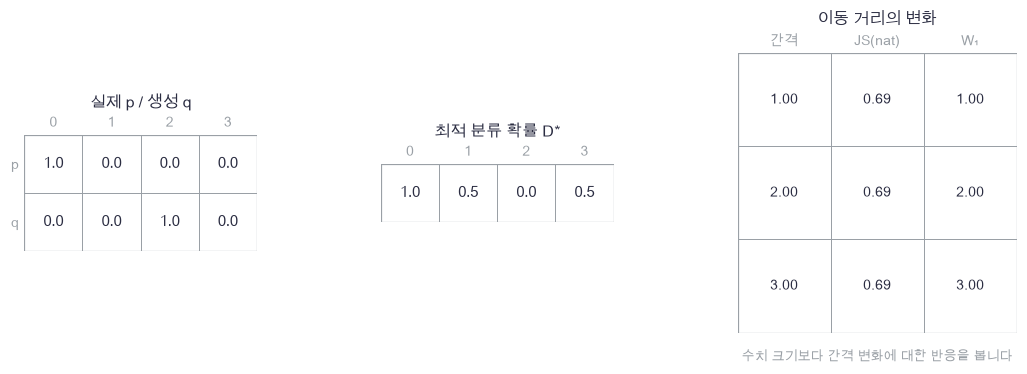

In [3]:
plot_distribution_distances(np.stack([p_mass, q_mass]), optimal_d[None, :],
                            distance_comparison, ["0", "1", "2", "3"])

🔍 **확인** · 가운데 분류 확률은 실제 위치에서 1, 생성 위치에서 0입니다. 오른쪽에서는 간격이 늘어도 JS는 그대로이고 W₁만 늘어납니다. 단위가 다른 JS와 W₁의 크기 순서를 품질 순위로 읽지 마세요.

In [4]:
def wasserstein_1d_loop(positions, p, q):
    """정렬된 유한 공통 지지점에서 CDF 차이의 구간 넓이를 반복문으로 더합니다."""
    accumulated = 0.0
    distance = 0.0
    for j in range(len(positions) - 1):
        accumulated += p[j] - q[j]
        distance += abs(accumulated) * (positions[j + 1] - positions[j])
    return float(distance)

In [5]:
def wasserstein_1d(positions, p, q):
    """합이1인 두 질량 배열의 1차원 W₁을 벡터화합니다."""
    assert np.all(np.diff(positions) > 0), "공통 위치는 엄격히 증가해야 합니다"
    assert np.all(p >= 0), "p는 음수 질량을 가지면 안 됩니다"
    assert np.all(q >= 0), "q는 음수 질량을 가지면 안 됩니다"
    assert np.isclose(np.sum(p), 1), "p의 질량 합은1이어야 합니다"
    assert np.isclose(np.sum(q), 1), "q의 질량 합은1이어야 합니다"
    return float(np.sum(np.abs(np.cumsum(p - q)[:-1]) * np.diff(positions)))

In [6]:
def js_discrete(p, q):
    """0 질량의 log0 계산을 제외하고 이산 JS를 계산합니다."""
    middle = (p + q) / 2
    p_positive, q_positive = p > 0, q > 0
    left = np.sum(p[p_positive] * np.log(p[p_positive] / middle[p_positive]))
    right = np.sum(q[q_positive] * np.log(q[q_positive] / middle[q_positive]))
    return float((left + right) / 2)

In [7]:
# 쓰는 것: positions, p_mass, q_mass (1절 그림), wasserstein_1d_loop (1절)
for gap in [1, 2, 3]:
    shifted = np.zeros(4)
    shifted[gap] = 1
    assert np.isclose(wasserstein_1d(positions, p_mass, shifted), gap), "W₁은 점 사이 간격이어야 합니다"
    assert np.isclose(js_discrete(p_mass, shifted), np.log(2)), "분리된 점질량 JS는 log2여야 합니다"
assert wasserstein_1d_loop(positions, p_mass, q_mass) == 2, "반복문은 손계산2와 같아야 합니다"
assert wasserstein_1d(positions, p_mass, p_mass) == 0, "같은 분포의 거리는0이어야 합니다"
print("손계산·반복문·벡터화 및 같은/분리된 분포 검산 통과")

손계산·반복문·벡터화 및 같은/분리된 분포 검산 통과


📎 **참고** · 다차원에서는 위 CDF 합을 그대로 쓸 수 없습니다. WGAN은 다음 쌍대 표현을 동기로 사용합니다.

$$W_1(P,Q)=\sup_{\operatorname{Lip}(f)\le1}\{\mathbb E_P f(x)-\mathbb E_Q f(x)\}.$$

> **용어** · **1-Lipschitz 함수**: $|f(x)-f(y)|\le\|x-y\|_2$인 함수입니다. 입력이 움직인 거리보다 점수가 더 크게 바뀌지 않습니다. **쌍대 표현**은 같은 최적값을 질량 이동 대신 함수의 점수 차로 표현하는 방식입니다.

실제로는 제한된 신경망을 몇 번 학습하고 유한 표본 평균을 냅니다. 따라서 학습 중 출력하는 critic gap을 참 $W_1$이라고 부르지 않습니다. 원리의 출처는 [Wasserstein GAN 원문](https://arxiv.org/abs/1701.07875)입니다.

### ✏️ 연습 1 · 누적 차이에 구간 길이를 곱하기

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

CDF 차이의 절댓값과 구간 길이를 곱해 모두 더한 distance를 채우세요.

In [8]:
def exercise_cdf(positions, p, q):
    """누적 차이에 구간 길이를 곱하기의 핵심 계산을 완성합니다."""
    cdf_difference = np.cumsum(p - q)[:-1]
    ### 이 주석 아래에 다음을 구현하세요.
    ### 구현할 내용: CDF 차이의 절댓값과 구간 길이를 곱해 모두 더한 distance를 채우세요.
    raise NotImplementedError
    return distance

In [9]:
def check_cdf(candidate):
    """손계산과 경계 입력으로 정답을 독립 확인합니다."""
    value = candidate(np.array([0., 1., 3.]), np.array([1., 0., 0.]), np.array([0., 0., 1.]))
    assert np.isclose(value, 3), "길이1과2의 두 구간 비용 합은3이어야 합니다"
    assert candidate(np.array([0., 2.]), np.array([.5, .5]), np.array([.5, .5])) == 0, "같은 분포는0이어야 합니다"
    print("연습 1 통과")

run_check(check_cdf, exercise_cdf, hint="누적 차이에 구간 길이를 곱하기의 수식을 한 줄씩 옮겨 보세요.")

☐ exercise_cdf: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 누적 차이에 구간 길이를 곱하기의 수식을 한 줄씩 옮겨 보세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
distance = np.sum(np.abs(cdf_difference) * np.diff(positions))
```

</details>

## 🔑 2. critic 점수에서 생성기까지 기울기를 보냅니다

**이 절에서 가져갈 것:** 생성기의 실제 기울기는 점수 목적의 미분, critic 입력 미분, 생성기 미분을 차례로 곱한 것입니다.

가짜 점이 아주 나쁘다고 판정되어 점수 $f(\hat x)=-8$이라면, 생성기는 어떤 신호를 받을까요? 같은 점수라도 최소화할 목적을 바꾸면 신호가 달라집니다. $D(x)=\sigma(f(x))$라 두면 한 가짜 표본에서

| G 목적 | 값 | 점수 $f$에 대한 미분 |
|---|---|---|
| 원래 minimax | $\log(1-D)=-\operatorname{softplus}(f)$ | $-\sigma(f)$ |
| NS | $-\log D=\operatorname{softplus}(-f)$ | $\sigma(f)-1$ |
| Wasserstein | $-f$ | $-1$ |

$\operatorname{softplus}(u)=\log(1+e^u)$이고 구현은 `np.logaddexp(0,u)`입니다. 배치 평균에서는 각 미분을 가짜 표본 수 $N$으로 나눕니다. NS와 Wasserstein은 나쁜 가짜의 **점수 미분**을 유지하지만, critic이나 G의 tanh가 포화되면 전체 기울기는 여전히 작아질 수 있습니다.

> **용어** · **포화**는 입력이 커져 활성화의 기울기가 작아지는 상태입니다. **logit**은 sigmoid 전의 실수 점수입니다. NS에서는 분류 logit이고 WGAN에서는 같은 배열을 확률로 바꾸지 않습니다.
>
> **코드** · `np.logaddexp(0, u)`는 큰 $u$에서도 넘침 없이 softplus를 계산합니다. `np.column_stack`은 1차원 배열들을 열로 모읍니다. `_`는 이후 쓰지 않는 반환값입니다.

In [10]:
score_examples = np.array([-8., -2., 0., 2.])
score_probabilities = 1 / (1 + np.exp(-score_examples))
generator_losses = np.stack([np.logaddexp(0, -score_examples), -score_examples])
score_derivatives = np.stack([-score_probabilities, score_probabilities - 1, -np.ones(4)])

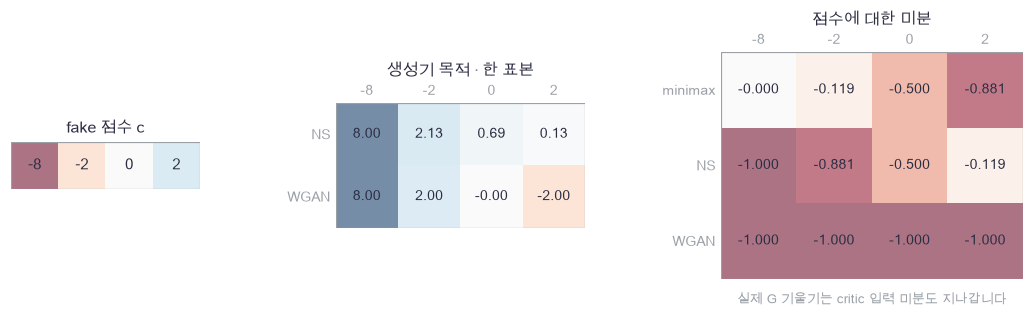

In [11]:
plot_generator_objectives(score_examples, generator_losses, score_derivatives)

🔍 **확인** · 점수 −8에서 minimax의 미분은 거의 0이지만 NS와 WGAN은 약 −1입니다. 이는 **점수 한 단계의 비교**입니다. 큰 음수 손실이 좋은 표본을 뜻하지도 않습니다. Wasserstein G 목적은 critic에 상수를 더하면 값이 바뀌지만 G에 전달하는 기울기는 바뀌지 않습니다.

모델은 모두 폭 $F$의 한 은닉층으로 고정합니다. $z\in\mathbb R^{N\times2}$,
$U:(2,F)$, $d:(F,)$, $V:(F,2)$, $e:(2,)$이고
$G(z)=\tanh(zU+d)V+e\in\mathbb R^{N\times2}$입니다. critic은

$$H=\tanh(XW+c):(N,F),\quad f(X)=Ha+b:(N,),\qquad W:(2,F),\ c:(F,),\ a:(F,),\ b:(1,).$$

은닉 폭 $F$와 은닉 배열 $H$를 구분합니다. 상류 점수 미분 $v:(N,)$에 대해 $dU=(v[:,None]\odot a)\odot(1-H^2)$,
$dW=X^TdU$, $dc=\sum_n dU_n$, $da=H^Tv$, $db=\sum_n v_n$, $dX=dUW^T$입니다.

최소화하는 두 critic 기본 목적은
$L_D^{NS}=\operatorname{mean}\operatorname{softplus}(-f(x))+\operatorname{mean}\operatorname{softplus}(f(\hat x))$와
$L_C^W=\operatorname{mean}f(\hat x)-\operatorname{mean}f(x)$입니다.
실제·가짜 표본 수가 다르면 각 평균의 분모도 따로 씁니다. 다음 절에서 WGAN 제약을 붙입니다.

> **코드** · `{name: value for ...}`는 이름과 배열을 연결한 사전을 만듭니다. `params["W"]`로 행렬을 고릅니다. `rng.normal(..., size)`는 정규 잡음을 뽑고 같은 seed는 같은 초기 배열을 줍니다. `.T`는 행렬 전치이며 `np.where`는 조건별 두 계산값을 고릅니다.

In [12]:
def stable_sigmoid(x):
    """극단 logit에서도 넘치지 않는 sigmoid를 계산합니다."""
    exponential = np.exp(-np.abs(x))
    return np.where(x >= 0, 1 / (1 + exponential), exponential / (1 + exponential))

In [13]:
def init_generator(seed, hidden=16):
    """잡음2 → tanh 은닉 → 표본2의 생성기 파라미터를 만듭니다."""
    rng = np.random.default_rng(seed)
    return {"W1": rng.normal(0, 0.5, (2, hidden)), "b1": np.zeros(hidden),
            "W2": rng.normal(0, 0.5 / np.sqrt(hidden), (hidden, 2)), "b2": np.zeros(2)}

In [14]:
def generator_forward(z, params):
    """잡음 (N,2)을 실제 생성 표본 (N,2)로 바꿉니다."""
    hidden = np.tanh(z @ params["W1"] + params["b1"])
    output = hidden @ params["W2"] + params["b2"]
    return output, (z, hidden, params["W1"], params["W2"])

In [15]:
def generator_backward(gradient, cache):
    """생성 표본 기울기를 모든 G 파라미터와 잡음 입력으로 돌려줍니다."""
    z, hidden, w1, w2 = cache
    du = (gradient @ w2.T) * (1 - hidden ** 2)
    gradients = {"W2": hidden.T @ gradient, "b2": np.sum(gradient, axis=0),
                 "W1": z.T @ du, "b1": np.sum(du, axis=0)}
    return du @ w1.T, gradients

In [16]:
def init_critic(seed, hidden=16):
    """표본2 → tanh 은닉 → 실수 점수1의 매끄러운 critic을 만듭니다."""
    rng = np.random.default_rng(seed)
    return {"W": rng.normal(0, 0.5, (2, hidden)), "c": np.zeros(hidden),
            "a": rng.normal(0, 1 / np.sqrt(hidden), hidden), "b": np.zeros(1)}

In [17]:
def critic_forward(x, params):
    """c(x)=tanh(xW+c)·a+b의 표본별 점수 (N,)를 계산합니다."""
    hidden = np.tanh(x @ params["W"] + params["c"])
    scores = hidden @ params["a"] + params["b"][0]
    return scores, (x, hidden, params["W"], params["a"])

In [18]:
def critic_backward(score_gradient, cache):
    """점수 상류 기울기에서 critic 파라미터 및 입력을 미분합니다."""
    x, hidden, weights, output_weights = cache
    du = score_gradient[:, None] * output_weights[None, :] * (1 - hidden ** 2)
    gradients = {"W": x.T @ du, "c": np.sum(du, axis=0),
                 "a": hidden.T @ score_gradient, "b": np.array([np.sum(score_gradient)])}
    return du @ weights.T, gradients

In [19]:
def critic_input_gradient(x, params):
    """각 표본의 critic 입력 기울기 g=(a⊙s)Wᵀ와 mixed 미분용 값을 반환합니다."""
    hidden = np.tanh(x @ params["W"] + params["c"])
    slope = 1 - hidden ** 2
    gradient = (slope * params["a"][None, :]) @ params["W"].T
    return gradient, (x, hidden, slope, params["W"], params["a"])

In [20]:
def discriminator_score_loss(real_scores, fake_scores, method):
    """최소화하는 NS 분류 손실 또는 Wasserstein critic 손실과 점수 미분입니다."""
    # 쓰는 것: stable_sigmoid (2절)
    if method == "NS":
        loss = np.mean(np.logaddexp(0, -real_scores)) + np.mean(np.logaddexp(0, fake_scores))
        real_gradient = (stable_sigmoid(real_scores) - 1) / len(real_scores)
        fake_gradient = stable_sigmoid(fake_scores) / len(fake_scores)
    else:
        assert method in ("WGAN-GP", "WGAN-SVD"), "정해진 세 방법 중 하나여야 합니다"
        loss = np.mean(fake_scores) - np.mean(real_scores)
        real_gradient = -np.ones_like(real_scores) / len(real_scores)
        fake_gradient = np.ones_like(fake_scores) / len(fake_scores)
    return float(loss), real_gradient, fake_gradient

In [21]:
def generator_score_loss(fake_scores, method):
    """NS는 softplus(-c), Wasserstein은 -c를 최소화합니다."""
    # 쓰는 것: stable_sigmoid (2절)
    if method == "NS":
        return float(np.mean(np.logaddexp(0, -fake_scores))), (stable_sigmoid(fake_scores) - 1) / len(fake_scores)
    assert method in ("WGAN-GP", "WGAN-SVD"), "정해진 세 방법 중 하나여야 합니다"
    return float(-np.mean(fake_scores)), -np.ones_like(fake_scores) / len(fake_scores)

In [22]:
def generator_objective(z, generator, critic, method):
    """critic은 고정하고 critic의 입력 미분을 거쳐 G만 미분합니다."""
    # 쓰는 것: generator_forward, generator_backward, critic_forward, critic_backward, generator_score_loss (2절)
    fake, generator_cache = generator_forward(z, generator)
    scores, critic_cache = critic_forward(fake, critic)
    loss, score_gradient = generator_score_loss(scores, method)
    fake_gradient, _ = critic_backward(score_gradient, critic_cache)
    dz, gradients = generator_backward(fake_gradient, generator_cache)
    return loss, gradients, dz

🔍 **확인** · 작은 폭 3에서 파라미터의 **모든 원소**와 입력을 중심차분합니다. 손 backward의 배열을 원소별로 $[L(\theta+he_i)-L(\theta-he_i)]/(2h)$와 비교합니다. 함수가 바라보는 배열을 조금 움직였다가 원래 값으로 돌리는 `numerical_gradient`를 사용합니다. 이후 GP도 같은 검사기를 씁니다.

> **코드** · 함수 안의 작은 `objective()`는 주변의 현재 배열을 읽는 함수입니다. `dict.items()`는 이름·배열 쌍, `.values()`는 배열만 순회합니다. `**`는 사전 항목을 다른 사전에 풀어 넣습니다.

In [23]:
def check_all_gradients(objective, arrays, gradients):
    """주어진 모든 실수 배열의 모든 원소를 중심차분하고 최대 절대오차를 반환합니다."""
    # 쓰는 것: numerical_gradient (준비 셀)
    errors = []
    for name, value in arrays.items():
        numeric = numerical_gradient(objective, value)
        np.testing.assert_allclose(gradients[name], numeric, atol=3e-7, rtol=3e-5)  # 검산: 손미분 = 모든 원소 중심차분
        errors.append(float(np.max(np.abs(gradients[name] - numeric))))
    return max(errors)

In [24]:
def check_ordinary_backward():
    """임의 상류 미분의 critic과 실제 NS/WGAN G 목적을 입력까지 전수 검산합니다."""
    # 쓰는 것: init_critic, init_generator, critic_forward, critic_backward, generator_objective (2절)
    # 쓰는 것: check_all_gradients (2절)
    rng = np.random.default_rng(2901)
    critic = init_critic(1, hidden=3)
    generator = init_generator(2, hidden=3)
    x, z = rng.normal(size=(3, 2)), rng.normal(size=(3, 2))
    upstream = rng.normal(size=3)
    _, cache = critic_forward(x, critic)
    dx, gradients = critic_backward(upstream, cache)
    def critic_scalar():
        """임의 상류 미분과 critic 출력의 내적입니다."""
        return float(np.sum(critic_forward(x, critic)[0] * upstream))
    errors = [check_all_gradients(critic_scalar, {**critic, "x": x}, {**gradients, "x": dx})]
    for method in ["NS", "WGAN-GP", "WGAN-SVD"]:
        _, gradients, dz = generator_objective(z, generator, critic, method)
        def generator_scalar():
            """critic 고정 상태에서 현재 방식의 G 목적을 계산합니다."""
            return generator_objective(z, generator, critic, method)[0]
        errors.append(check_all_gradients(generator_scalar, {**generator, "z": z}, {**gradients, "z": dz}))
    return max(errors)

In [25]:
# 쓰는 것: stable_sigmoid, generator_score_loss (2절)
ordinary_error = check_ordinary_backward()
np.testing.assert_allclose(stable_sigmoid(np.array([-1000., 0., 1000.])), [0., .5, 1.])  # 검산: 극단 sigmoid의 유한값
extreme_loss, extreme_gradient = generator_score_loss(np.array([-1000., 1000.]), "NS")
assert np.isfinite(extreme_loss), "극단 NS 손실은 유한해야 합니다"
assert np.all(np.isfinite(extreme_gradient)), "극단 NS 기울기는 유한해야 합니다"
print(f"일반 backward 및 실제 G 목적 검산 통과 · 최대 절대오차 {ordinary_error:.2e}")

일반 backward 및 실제 G 목적 검산 통과 · 최대 절대오차 7.87e-11


### ✏️ 연습 2 · 배치 평균의 G 점수 기울기

주어진 확률 p에 대해 NS 생성기 점수 기울기 gradient를 채우세요.

In [26]:
def exercise_ns_gradient(p):
    """배치 평균의 G 점수 기울기의 핵심 계산을 완성합니다."""
    ### 이 주석 아래에 다음을 구현하세요.
    ### 구현할 내용: 주어진 확률 p에 대해 NS 생성기 점수 기울기 gradient를 채우세요.
    raise NotImplementedError
    return gradient

In [27]:
def check_ns_gradient(candidate):
    """손계산과 경계 입력으로 정답을 독립 확인합니다."""
    np.testing.assert_allclose(candidate(np.array([.2, .8])), [-.4, -.1])  # 검산: 평균 분모2 적용
    np.testing.assert_allclose(candidate(np.array([0.])), [-1.])  # 검산: 아주 나쁜 가짜의 점수 미분
    print("연습 2 통과")

run_check(check_ns_gradient, exercise_ns_gradient, hint="배치 평균의 G 점수 기울기의 수식을 한 줄씩 옮겨 보세요.")

☐ exercise_ns_gradient: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 배치 평균의 G 점수 기울기의 수식을 한 줄씩 옮겨 보세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
gradient = (p - 1) / len(p)
```

</details>

## 🔑 3. 입력 기울기의 크기도 파라미터로 미분합니다

**이 절에서 가져갈 것:** GP backward에는 critic의 입력 미분에 나타나는 $W$의 직접 경로와 tanh를 거치는 간접 경로가 모두 필요합니다.

실제 점과 가짜 점 사이를 잇는 선분에 작은 자를 놓는다고 생각해 봅시다. 그 위치에서 critic 점수가 얼마나 가파른지 재고, 기울기 크기를 1 근처로 유도합니다. 실수 점수에 sigmoid를 붙이지 않습니다.

$$\hat X=\alpha X+(1-\alpha)\widetilde X,\quad \alpha:(N,1),\quad
 g=\nabla_{\hat X}f=(s\odot a)W^T:(N,2),\quad s=1-H^2.$$
$$r_i=\sqrt{\|g_i\|_2^2+\epsilon},\qquad GP=\frac1N\sum_i(r_i-1)^2,\qquad L_C=L_C^W+\lambda GP.$$

각 행의 $\alpha$는 두 좌표에 함께 곱합니다. 여기서는 $\epsilon=10^{-12}$를 **norm의 제곱에 더한 뒤** 제곱근을 취합니다. 따라서 norm의 바닥은 $10^{-6}$입니다. 원래 norm 대신 부드러운 norm을 쓰는 작은 수치적 변경이며, 아래 미분도 이 실제 forward와 정확히 맞춥니다.

> **용어** · **gradient penalty(GP)**는 입력 기울기의 크기에 붙이는 벌점입니다. **보간(interpolation)**은 두 점 사이를 가중합으로 고르는 것입니다. GP는 뽑힌 보간점에서의 제약이며 전역 1-Lipschitz를 보장하지 않습니다. 출처: [Improved Training of Wasserstein GANs](https://arxiv.org/abs/1704.00028).

In [28]:
# 쓰는 것: init_critic (2절)
gp_real = np.array([[-1., -1.], [1., 1.], [-1., 1.]])
gp_fake = np.array([[.5, -.5], [-.5, .2], [.1, -.7]])
gp_alpha = np.array([[.2], [.5], [.8]])
gp_points = gp_alpha * gp_real + (1 - gp_alpha) * gp_fake
gp_parameters = init_critic(2903, hidden=3)
gp_hidden = np.tanh(gp_points @ gp_parameters["W"] + gp_parameters["c"])
gp_slopes = 1 - gp_hidden ** 2
gp_input_gradient = (gp_slopes * gp_parameters["a"][None, :]) @ gp_parameters["W"].T
gp_norms = np.sqrt(np.sum(gp_input_gradient ** 2, axis=1) + 1e-12)
gp_penalties = (gp_norms - 1) ** 2

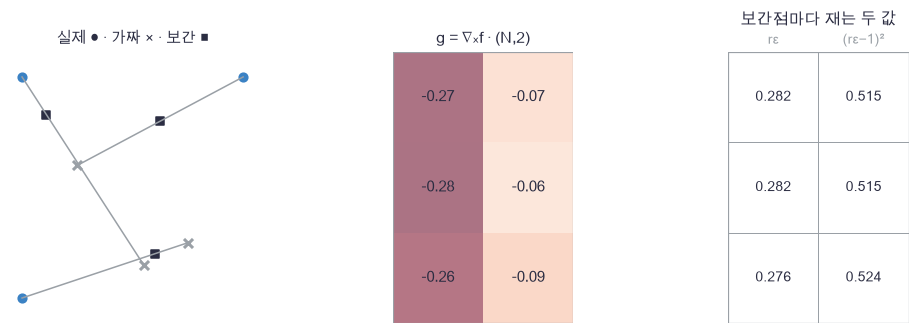

In [29]:
plot_gp_path(gp_real, gp_fake, gp_points, gp_input_gradient, gp_norms, gp_penalties)

🔍 **확인** · 선분의 사각형이 벌점을 재는 위치입니다. 오른쪽은 **표본마다 norm을 먼저 구한 뒤** 벌점을 계산합니다. 배치 평균 기울기의 norm을 재는 식과 다릅니다. D 단계에서는 생성 표본과 $\alpha$를 상수로 고정합니다.

다음 식은 $\lambda$를 곱하기 전 GP 자체의 미분입니다.

$$v_i=\frac{\partial GP}{\partial g_i}=\frac{2(r_i-1)}{Nr_i}g_i,\quad
 T=vW:(N,F),\quad dU=T\odot a\odot(-2Hs).$$
$$dW=\underbrace{v^T(s\odot a)}_{g\text{의 }W^T\text{ 직접 경로}}+
 \underbrace{\hat X^TdU}_{H=\tanh(\hat XW+c)\text{ 경로}},\quad
 dc=\sum_i dU_i,\quad da=\sum_i(T\odot s)_i,\quad db=0,\quad d\hat X=dUW^T.$$

$tanh'(u)=s$, $s'(u)=-2Hs$를 사용했습니다. $v:(N,2)$라서 직접 항은 $(2,N)@(N,F)=(2,F)$입니다. 출력 bias $b$는 입력 미분에서 사라져 GP 기울기가 0입니다. $d\hat X$는 검산용으로도 계산하지만, critic 갱신 때 G로 보내지는 않습니다.

In [30]:
def gradient_penalty(x, params, epsilon=1e-12):
    """mean(sqrt(||∇c||²+ε)-1)²와 모든 critic 파라미터·입력의 정확한 미분입니다."""
    # 쓰는 것: critic_input_gradient (2절)
    assert epsilon > 0, "norm 안에 더하는 epsilon은 양수여야 합니다"
    # 1) critic 입력 기울기와 부드러운 norm을 계산합니다.
    g, cache = critic_input_gradient(x, params)
    inputs, hidden, slope, weights, output_weights = cache
    norms = np.sqrt(np.sum(g ** 2, axis=1) + epsilon)
    penalty = np.mean((norms - 1) ** 2)
    v = (2 * (norms - 1) / (len(x) * norms))[:, None] * g
    # 2) g의 직접 W 경로와 tanh 도함수를 지나는 간접 경로를 나눕니다.
    v_weights = v @ weights
    du = v_weights * output_weights[None, :] * (-2 * hidden * slope)
    gradients = {
        "W": v.T @ (slope * output_weights[None, :]) + inputs.T @ du,
        "c": np.sum(du, axis=0),
        "a": np.sum(v_weights * slope, axis=0),
        "b": np.zeros(1),
    }
    dx = du @ weights.T
    return float(penalty), gradients, dx, norms

In [31]:
def critic_objective(real, fake, params, method, alpha, gp_weight=10.0):
    """G 표본을 고정한 critic 목적의 실제 모든 파라미터 기울기를 구합니다."""
    # 쓰는 것: critic_forward, critic_backward, discriminator_score_loss (2절), gradient_penalty (3절)
    real_scores, real_cache = critic_forward(real, params)
    fake_scores, fake_cache = critic_forward(fake, params)
    base, dreal, dfake = discriminator_score_loss(real_scores, fake_scores, method)
    _, real_gradients = critic_backward(dreal, real_cache)
    _, fake_gradients = critic_backward(dfake, fake_cache)
    gradients = {name: real_gradients[name] + fake_gradients[name] for name in params}
    penalty = 0.0
    if method == "WGAN-GP":
        interpolated = alpha * real + (1 - alpha) * fake
        penalty, penalty_gradients, _, _ = gradient_penalty(interpolated, params)
        for name in gradients:
            gradients[name] += gp_weight * penalty_gradients[name]
    return float(base + gp_weight * penalty), gradients, {"base": base, "penalty": penalty}

In [32]:
def check_gp_backward():
    """고정 보간·두 epsilon에서 GP와 전체 D 목적의 모든 파라미터를 검산합니다."""
    # 쓰는 것: init_critic (2절), gradient_penalty, critic_objective (3절), check_all_gradients (2절)
    rng = np.random.default_rng(2904)
    real, fake = rng.normal(size=(3, 2)), rng.normal(size=(3, 2))
    alpha = rng.uniform(size=(3, 1))
    interpolated = alpha * real + (1 - alpha) * fake
    params = init_critic(11, hidden=3)
    params["c"][:] = np.array([.1, -.2, .3])
    errors = []
    # 1) 보간점 자체와 모든 파라미터를 같은 고정 목적에서 움직입니다.
    for epsilon in [1e-12, 0.03]:
        _, gradients, dx, _ = gradient_penalty(interpolated, params, epsilon)
        def gp_scalar():
            """고정 epsilon의 GP를 다시 계산합니다."""
            return gradient_penalty(interpolated, params, epsilon)[0]
        errors.append(check_all_gradients(gp_scalar, {**params, "x": interpolated}, {**gradients, "x": dx}))
    # 2) 실제 NS/Wasserstein 기본항과 λGP 합도 별도로 검사합니다.
    for method in ["NS", "WGAN-GP", "WGAN-SVD"]:
        _, gradients, _ = critic_objective(real, fake, params, method, alpha)
        def full_scalar():
            """real·fake·alpha를 다시 뽑지 않고 현재 D 목적을 계산합니다."""
            return critic_objective(real, fake, params, method, alpha)[0]
        errors.append(check_all_gradients(full_scalar, params, gradients))
    return max(errors)

In [33]:
# 쓰는 것: init_critic (2절), gp_points (3절 그림), gradient_penalty (3절)
gp_error = check_gp_backward()
zero_critic = init_critic(2905, hidden=3)
zero_critic["a"][:] = 0
zero_penalty, zero_gradients, zero_dx, zero_norms = gradient_penalty(gp_points, zero_critic)
assert np.isclose(zero_penalty, (1e-6 - 1) ** 2), "영 기울기의 GP는 약1이어야 합니다"
for value in zero_gradients.values():
    assert np.all(value == 0), "g=0이면 이 부드러운 GP의 파라미터 미분은0이어야 합니다"
assert np.all(zero_dx == 0), "g=0이면 GP 입력 미분도0이어야 합니다"
print(f"고정 보간의 GP·전체 D 목적 검산 통과 · 최대 절대오차 {gp_error:.2e}")
print("영 입력 기울기: penalty", zero_penalty, "이지만 GP gradient는0")

고정 보간의 GP·전체 D 목적 검산 통과 · 최대 절대오차 1.05e-09
영 입력 기울기: penalty 0.9999980000009999 이지만 GP gradient는0


🔍 **확인** · $g=0$에서는 벌점이 약 1이어도 $v=0$이므로 이 GP의 미분이 0입니다. 큰 벌점이 항상 탈출 신호를 준다는 보장은 없습니다. 수치검산에서 $\alpha$를 매번 다시 뽑으면 다른 함수를 빼는 셈이므로, 차분 폭을 줄여도 정답 미분에 가까워지지 않습니다.

### ✏️ 연습 3 · norm 벌점을 g로 미분하기

GP를 g로 미분한 v를 채우세요. 배치 평균과 epsilon이 포함된 norms를 사용합니다.

In [34]:
def exercise_gp_v(g, epsilon):
    """norm 벌점을 g로 미분하기의 핵심 계산을 완성합니다."""
    norms = np.sqrt(np.sum(g ** 2, axis=1) + epsilon)
    ### 이 주석 아래에 다음을 구현하세요.
    ### 구현할 내용: GP를 g로 미분한 v를 채우세요. 배치 평균과 epsilon이 포함된 norms를 사용합니다.
    raise NotImplementedError
    return v

In [35]:
def check_gp_v(candidate):
    """손계산과 경계 입력으로 정답을 독립 확인합니다."""
    g = np.array([[3., 0.], [0., 0.]])
    expected = np.array([[(np.sqrt(10) - 1) * 3 / np.sqrt(10), 0.], [0., 0.]])
    np.testing.assert_allclose(candidate(g, 1.), expected)  # 검산: 평균2·norm=sqrt(10)·영 기울기
    print("연습 3 통과")

run_check(check_gp_v, exercise_gp_v, hint="norm 벌점을 g로 미분하기의 수식을 한 줄씩 옮겨 보세요.")

☐ exercise_gp_v: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: norm 벌점을 g로 미분하기의 수식을 한 줄씩 옮겨 보세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
v = (2 * (norms - 1) / (len(g) * norms))[:, None] * g
```

</details>

## 🔑 4. 특잇값을 제한하면 무엇이 보장될까요?

**이 절에서 가져갈 것:** 층의 연산자 norm을 제한하면 이 모델의 전역 Lipschitz 상한을 제한할 수 있지만, 표현력과 생성 품질은 별개의 문제입니다.

critic의 가중치를 한 번 고쳤더니 어떤 방향은 2배, 다른 방향은 0.5배로 늘린다고 합시다. 모든 방향을 절반으로 줄이는 대신 **1을 넘는 늘림만 잘라내는** 제약을 생각할 수 있습니다.

$$W=U\operatorname{diag}(\sigma)V^T,\qquad
 \Pi(W)=U\operatorname{diag}(\min(\sigma,1))V^T.$$

행렬의 spectral norm은 가장 큰 특잇값입니다. 이 식은 $\|W\|_2\le1$인 집합으로의 **Frobenius 거리상 최단 투영**입니다. `diag(2, .5)`는 `diag(1, .5)`로 바뀝니다. 행렬 전체를 2로 나누어 `diag(1, .25)`로 만드는 재조정과 다릅니다.

> **용어**
>
> - **spectral norm** $\|W\|_2$: 단위 길이 벡터가 행렬을 거쳐 가장 크게 늘어나는 비율입니다. `np.linalg.svd(..., compute_uv=False)[0]`입니다.
> - **Frobenius norm**: 행렬 원소 제곱을 모두 더해 제곱근을 취한 값입니다. 투영 전후 행렬의 차이를 재는 데 씁니다.
> - **사후 투영(projection)**: optimizer가 파라미터를 고친 다음 허용 집합으로 옮기는 연산입니다. 다음 forward가 그 행렬을 사용합니다.
>
> **코드** · `np.linalg.svd(W, full_matrices=False)`는 필요한 크기의 `U, singular, Vt`를 반환합니다. `U * singular[None, :]`는 U의 열마다 특잇값을 곱합니다. `.ravel()`은 열벡터를 1차원으로 펴 줍니다.

In [36]:
projection_matrix = np.diag([2., 0.5])
projection_left, projection_singular, projection_right = np.linalg.svd(projection_matrix, full_matrices=False)
projection_clipped = np.minimum(projection_singular, 1.)
projection_result = (projection_left * projection_clipped[None, :]) @ projection_right

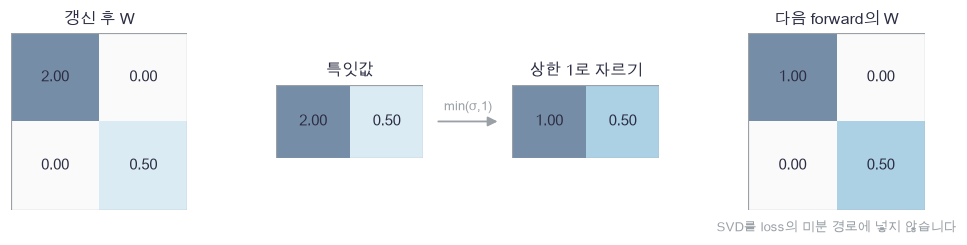

In [37]:
plot_spectral_projection(projection_matrix, projection_singular, projection_clipped, projection_result)

🔍 **확인** · 큰 특잇값 2만 1이 되고 0.5는 보존됩니다. 그림의 SVD는 loss를 미분하는 경로가 아니라 **갱신 뒤에 적용하는 제약**입니다. 그러므로 이 구현에는 SVD backward가 없습니다.

$tanh$는 각 좌표에서 기울기 크기가 1 이하입니다. 현재 구조의 점수는

$$|f(x)-f(y)|\le\|W\|_2\|a\|_2\,\|x-y\|_2$$

를 만족합니다. $W$와 열벡터 $a$를 각각 norm 1 이하로 투영하면 전역 1-Lipschitz 상한을 얻습니다. 출력 bias는 점수 차에서 직접 소거됩니다. 은닉 bias는 tanh의 전역 기울기 상한1을 바꾸지 않으므로 둘 다 제약하지 않습니다. 이 **상한**이 실제 모든 위치의 기울기 크기와 같다는 뜻은 아닙니다. 작고 제한된 critic은 분포 차이를 충분히 표현하지 못할 수 있습니다.

[원 Spectral Normalization 논문](https://arxiv.org/abs/1802.05957)은 forward에서 가중치를 spectral norm으로 정규화하는 매개화와 그 추정을 사용합니다. 여기의 정확 SVD **특잇값 자르기·사후 투영**은 그 알고리즘을 재현한 것이 아닙니다. 비교표 이름을 `WGAN-SVD`로 두어 구분합니다. Adam 상태는 그대로 두고 파라미터만 투영하며, 이 조합의 수렴을 보장한다고 주장하지 않습니다.

In [38]:
def spectral_projection(matrix, limit=1.0):
    """SVD의 각 특잇값을 잘라 spectral-norm ball에 Frobenius 최단 투영합니다."""
    assert limit > 0, "spectral norm 상한은 양수여야 합니다"
    left, singular, right = np.linalg.svd(matrix, full_matrices=False)
    clipped = np.minimum(singular, limit)
    return (left * clipped[None, :]) @ right

In [39]:
def project_critic(params):
    """업데이트 뒤 W와 a 열벡터를 각각 norm≤1로 투영하며 bias는 그대로 둡니다."""
    # 쓰는 것: spectral_projection (4절)
    params["W"] = spectral_projection(params["W"])
    params["a"] = spectral_projection(params["a"][:, None]).ravel()

In [40]:
def critic_lipschitz_bound(params):
    """tanh의 기울기 상한1을 써 전체 critic의 ||W||₂||a||₂ 상한을 계산합니다."""
    return float(np.linalg.svd(params["W"], compute_uv=False)[0] * np.linalg.norm(params["a"]))

In [41]:
def check_projection():
    """직사각형 투영·재투영·critic norm 상한과 bias 보존을 검산합니다."""
    # 쓰는 것: spectral_projection, project_critic, critic_lipschitz_bound (4절)
    # 쓰는 것: init_critic, critic_input_gradient, critic_forward (2절)
    rng = np.random.default_rng(2906)
    matrix = rng.normal(size=(2, 5))
    projected = spectral_projection(matrix)
    assert np.linalg.norm(projected, ord=2) <= 1 + 1e-12, "최대 특잇값은1이하여야 합니다"
    np.testing.assert_allclose(spectral_projection(projected), projected, atol=1e-12)  # 검산: 재투영 = 첫 투영
    np.testing.assert_allclose(spectral_projection(np.diag([2., .5])), np.diag([1., .5]))  # 검산: 손계산
    params = init_critic(2907, hidden=5)
    params["c"][:] = .3
    params["b"][:] = -.7
    project_critic(params)
    bound = critic_lipschitz_bound(params)
    assert bound <= 1 + 1e-12, "두 층 norm의 곱은1이하여야 합니다"
    assert np.all(params["c"] == .3), "은닉 bias는 바뀌지 않아야 합니다"
    assert params["b"][0] == -.7, "출력 bias는 바뀌지 않아야 합니다"
    x, y = rng.normal(size=(40, 2)), rng.normal(size=(40, 2))
    gradients, _ = critic_input_gradient(x, params)
    assert np.max(np.linalg.norm(gradients, axis=1)) <= bound + 1e-12, "입력 기울기는 증명한 상한 이하여야 합니다"
    difference = np.abs(critic_forward(x, params)[0] - critic_forward(y, params)[0])
    assert np.all(difference <= bound * np.linalg.norm(x - y, axis=1) + 1e-12), "점수 차는 Lipschitz 상한을 지켜야 합니다"
    return bound

In [42]:
projection_bound = check_projection()
print(f"특잇값 투영과 전역 상한의 표본 검산 통과 · 상한 {projection_bound:.4f}")

특잇값 투영과 전역 상한의 표본 검산 통과 · 상한 1.0000


🔍 **확인** · 무작위 점에서 부등식을 확인하는 것만으로 전역 성질을 증명한 것은 아닙니다. 전역 상한은 앞의 층별 norm 부등식에서 나왔고, 검사는 그 수식과 구현이 어긋나는 실수를 잡습니다. GP의 표본별 벌점과 사후 투영의 전역 상한은 다른 종류의 제약입니다.

### ✏️ 연습 4 · 큰 특잇값만 잘라내기

주어진 특잇값 배열을 limit 이하로 자른 clipped를 채우세요.

In [43]:
def exercise_singular(singular, limit):
    """큰 특잇값만 잘라내기의 핵심 계산을 완성합니다."""
    ### 이 주석 아래에 다음을 구현하세요.
    ### 구현할 내용: 주어진 특잇값 배열을 limit 이하로 자른 clipped를 채우세요.
    raise NotImplementedError
    return clipped

In [44]:
def check_singular(candidate):
    """손계산과 경계 입력으로 정답을 독립 확인합니다."""
    np.testing.assert_allclose(candidate(np.array([2., .5, 0.]), 1.), [1., .5, 0.])  # 검산: 작은 방향은 보존
    np.testing.assert_allclose(candidate(np.array([.4, .2]), .3), [.3, .2])  # 검산: 상한 변경
    print("연습 4 통과")

run_check(check_singular, exercise_singular, hint="큰 특잇값만 잘라내기의 수식을 한 줄씩 옮겨 보세요.")

☐ exercise_singular: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 큰 특잇값만 잘라내기의 수식을 한 줄씩 옮겨 보세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
clipped = np.minimum(singular, limit)
```

</details>

## 🔑 5. 같은 예산에서 품질·coverage·seed를 함께 읽습니다

**이 절에서 가져갈 것:** 제약의 진단값, 생성 표본의 품질, mode coverage를 분리하고 모든 seed를 같은 조건에서 비교합니다.

네 모서리에 과일 묶음이 놓여 있다고 생각해 봅시다. 한 묶음만 정밀하게 그리면 품질은 높아도 다양성이 없습니다. 반대로 넓은 바닥에 점을 뿌리면 모든 묶음에 몇 점씩 닿아도 대부분은 잘못된 위치입니다.

실제 분포는 네 중심 $(-1,-1),(-1,1),(1,-1),(1,1)$에 같은 확률을 주고 표준편차 0.08의 Gaussian 잡음을 더합니다. 생성 표본 $\tilde x_i$의 최근접 중심 거리가 반경 $r=0.3$ 이하면 **근접 표본**으로 셉니다.

$$quality=\frac{\#\{i:\min_k\|\tilde x_i-\mu_k\|\le r\}}{M},\quad
 n_k=\#\{\text{중심 }k\text{에 가장 가깝고 반경 안인 표본}\},\quad
 coverage=\frac{\#\{k:n_k\ge5\}}4.$$

분모 $M$에는 멀리 떨어진 표본도 포함합니다. 모든 생성 표본을 무조건 최근접 중심에 배정해 coverage를 세지 않습니다. 그래도 coverage 하나로는 충분하지 않으므로 quality와 실제 점 그림을 함께 봅니다. 두 지표는 알려진 합성 중심을 쓰는 진단이며 일반 이미지의 의미적 품질 지표가 아닙니다.

> **용어** · **coverage**는 여기서 최소 5개의 근접 표본을 가진 중심의 비율입니다. **held-out 표본**은 학습과 설정 선택에 쓰지 않은 독립 난수로 뽑은 평가 자료입니다. **mode collapse**는 생성 결과가 일부 봉우리에 몰리는 현상입니다.
>
> **코드** · `rng.integers(0,K,size=M)`은 중심 번호를 복원추출합니다. `samples[:,None,:] - centers[None,:,:]`는 모든 표본–중심 차이 `(M,K,2)`입니다. `np.argmin(...,axis=1)`은 각 표본의 최근접 중심을 고릅니다. `np.bincount(labels,minlength=K)`는 각 중심의 개수를 셉니다. `.copy()`는 원래 배열과 별도로 수정할 사본을 만듭니다. `np.arange(M)`은 표본별 행 번호입니다. `np.repeat(centers,5,axis=0)`는 각 행을 다섯 번 반복하고 `np.concatenate`는 배열을 기존 축으로 잇습니다. `np.arange(512) % 4`는 네 중심 번호를 차례로 반복합니다.

In [45]:
centers = np.array([[-1., -1.], [-1., 1.], [1., -1.], [1., 1.]])
concept_rng = np.random.default_rng(2908)
concept_reference = centers[np.arange(512) % 4] + concept_rng.normal(0, .08, (512, 2))
concept_collapse = centers[0] + concept_rng.normal(0, .08, (512, 2))
concept_spread = np.concatenate([np.repeat(centers, 5, axis=0), concept_rng.uniform(-3, 3, (492, 2))])
concept_candidates = [concept_reference, concept_collapse, concept_spread]
concept_qualities, concept_coverages = [], []
for candidate_points in concept_candidates:
    distances = np.sum((candidate_points[:, None, :] - centers[None, :, :]) ** 2, axis=2)
    labels = np.argmin(distances, axis=1)
    accepted = distances[np.arange(len(candidate_points)), labels] <= .3 ** 2
    counts = np.bincount(labels[accepted], minlength=4)
    concept_qualities.append(np.mean(accepted))
    concept_coverages.append(np.mean(counts >= 5))

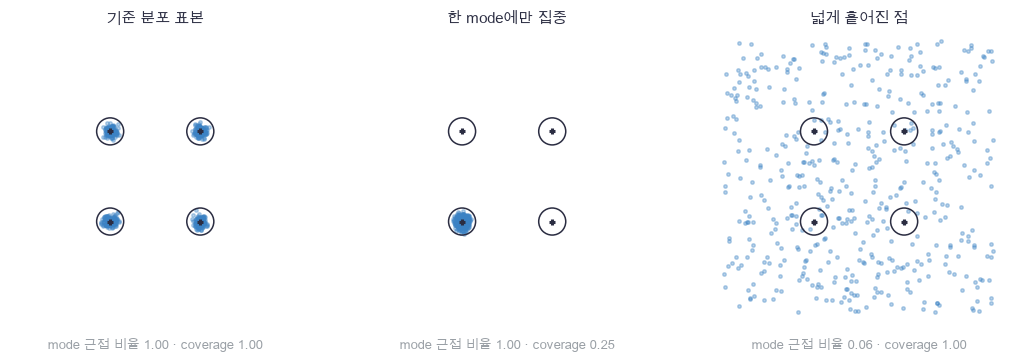

In [46]:
plot_quality_coverage(concept_candidates, ["기준 분포 표본", "한 mode에만 집중", "넓게 흩어진 점"],
                      centers, .3, concept_qualities, concept_coverages, (-3.2, 3.2))

🔍 **확인** · 이 그림은 **의도적으로 만든 진단 후보**이고 학습 결과가 아닙니다. 가운데는 근접 비율이 높아도 coverage가 1/4입니다. 오른쪽은 네 mode에 5개씩 미리 둔 점 때문에 coverage가 1이지만 대부분의 표본은 반경 밖입니다. 고정 표본 수·반경·최소 개수에서 두 숫자를 함께 읽어야 합니다.

실험 설정은 아래처럼 먼저 고정합니다. 뒤의 평가 결과를 보고 학습 횟수나 seed를 고르지 않습니다.

| 항목 | 모든 방법의 조건 |
|---|---|
| 방법 | NS, WGAN-GP(λ=10), WGAN-SVD(두 norm 상한1) |
| 모델 | G: 2→16 tanh→2, critic: 2→16 tanh→1; G 82개, critic 65개 학습 파라미터 |
| seed | 291, 292, 293; 각 seed 안에서 초기 G/D와 표본 계획 공유 |
| 초기 제약 | **세 방법 모두** 같은 초기 critic을 한 번 투영한 사본으로 시작 |
| 갱신 | G 160번, G 한 번마다 D 3번, 각 배치64 |
| optimizer | 각각 독립 Adam, 학습률.002, β₁=.5, β₂=.9, ε=1e−8 |
| 표본 예산 | 실제/critic 잡음 각각 30,720개, G 갱신 잡음 10,240개 |
| 진단 | 별도 고정 실제128·잡음128·α128, 0/40/80/120/160에서 측정 |
| 최종 평가 | 별도 독립 잡음1,024개와 실제1,024개, 모든 방법에 같은 잡음 |
| 평가 기준 | radius=.3, 중심당 최소5개; 평가·진단으로 설정 선택 없음 |

GP는 입력 기울기와 혼합 미분을 추가 계산하고, SVD 방식은 D 갱신마다 두 번 투영합니다. 같은 표본·갱신 예산이 **같은 연산량**은 아닙니다. 시간은 진단 측정을 포함한 학습 루프 시간으로 기록하며 이 작은 실행의 관찰일 뿐입니다.

In [47]:
def sample_modes(rng, count, centers, noise_std=0.08):
    """각 중심을 같은 확률로 고른 뒤 작은 Gaussian 잡음을 더합니다."""
    labels = rng.integers(0, len(centers), size=count)
    return centers[labels] + rng.normal(0, noise_std, (count, 2))

In [48]:
def mode_metrics(samples, centers, radius=0.3, minimum_count=5):
    """전체 표본을 분모로 근접 품질을 재고, 근접 표본만 mode별로 셉니다."""
    squared = np.sum((samples[:, None, :] - centers[None, :, :]) ** 2, axis=2)
    labels = np.argmin(squared, axis=1)
    nearest = squared[np.arange(len(samples)), labels]
    accepted = nearest <= radius ** 2
    counts = np.bincount(labels[accepted], minlength=len(centers))
    return {"quality": float(np.mean(accepted)), "coverage": float(np.mean(counts >= minimum_count)),
            "counts": counts, "distance": float(np.mean(np.sqrt(nearest)))}

In [49]:
# 쓰는 것: centers, concept_candidates, concept_qualities, concept_coverages (5절 그림)
for index, points in enumerate(concept_candidates):
    result = mode_metrics(points, centers)
    assert np.isclose(result["quality"], concept_qualities[index]), "함수와 직접 계산의 품질은 같아야 합니다"
    assert np.isclose(result["coverage"], concept_coverages[index]), "함수와 직접 계산의 coverage는 같아야 합니다"
far_result = mode_metrics(np.array([[100., 100.], [-100., -100.]]), centers)
assert far_result["quality"] == 0, "멀리 있는 점은 품질 분자에 들어가면 안 됩니다"
assert far_result["coverage"] == 0, "최근접 중심이 있어도 반경 밖이면 coverage에 세면 안 됩니다"
print("지표의 직접 배열·함수 및 멀리 떨어진 표본 검산 통과")

지표의 직접 배열·함수 및 멀리 떨어진 표본 검산 통과


In [50]:
def make_training_plan(seed, centers, steps=160, critic_steps=3, batch=64):
    """한 seed에서 세 방법이 공유할 실제 표본·잡음·고정 보간 계수를 미리 뽑습니다."""
    # 쓰는 것: sample_modes (5절)
    rng = np.random.default_rng(seed + 1000)
    shape = (steps, critic_steps, batch, 2)
    real = sample_modes(rng, steps * critic_steps * batch, centers).reshape(shape)
    return {"real": real, "critic_z": rng.normal(size=shape),
            "generator_z": rng.normal(size=(steps, batch, 2)),
            "alpha": rng.uniform(size=(steps, critic_steps, batch, 1))}

📎 **참고** · Adam의 1차·2차 상태는 G와 D가 따로 가집니다.
$m_t=\beta_1m_{t-1}+(1-\beta_1)g_t$,
$v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2$,
$\theta_t=\theta_{t-1}-\eta\{m_t/(1-\beta_1^t)\}/(\sqrt{v_t/(1-\beta_2^t)}+\epsilon)$입니다.
D의 시계는 480까지, G의 시계는 160까지 갑니다. GP의 norm 안 epsilon과 optimizer 분모의 epsilon은 역할과 값이 다릅니다.

기록할 critic gap은 `mean(real_score) - mean(fake_score)`입니다. 진단 입력 norm은 **같은 실제점·같은 잡음·같은 α**로 만든 현재 보간점에서 잽니다. G가 바뀌므로 그 잡음의 생성점은 움직입니다. G 기울기 norm은 그 방법의 실제 G 목적에 대한 모든 파라미터 미분을 한 벡터로 보아 잽니다. 목적 단위가 달라 norm의 크기만으로 방법을 순위 매기지 않습니다.

> **코드** · `sum(np.sum(value**2) for value in gradients.values())`는 여러 파라미터 배열의 제곱합을 하나로 더합니다. `(0, *values)`는 값들 앞에 스텝0을 붙입니다. `(method, seed)`라는 튜플을 사전의 키로 사용하여 모든 실행을 보존합니다.

In [51]:
def init_adam(params):
    """파라미터마다 독립인 1차·2차 모멘트와 갱신 횟수를 만듭니다."""
    return {"m": {name: np.zeros_like(value) for name, value in params.items()},
            "v": {name: np.zeros_like(value) for name, value in params.items()}, "t": 0}

In [52]:
def adam_step(params, gradients, state, learning_rate=0.002, beta1=0.5, beta2=0.9):
    """각 optimizer의 고유 시계로 편향을 보정한 Adam 갱신을 제자리 수행합니다."""
    state["t"] += 1
    for name in params:
        state["m"][name] = beta1 * state["m"][name] + (1 - beta1) * gradients[name]
        state["v"][name] = beta2 * state["v"][name] + (1 - beta2) * gradients[name] ** 2
        first = state["m"][name] / (1 - beta1 ** state["t"])
        second = state["v"][name] / (1 - beta2 ** state["t"])
        params[name] -= learning_rate * first / (np.sqrt(second) + 1e-8)

In [53]:
def measure_diagnostics(generator, critic, method, validation):
    """고정 진단 표본에서 gap·입력 기울기·현재 G 목적의 기울기를 기록합니다."""
    # 쓰는 것: generator_forward, critic_forward, critic_input_gradient, generator_objective (2절)
    real, z, alpha = validation
    fake, _ = generator_forward(z, generator)
    real_scores, _ = critic_forward(real, critic)
    fake_scores, _ = critic_forward(fake, critic)
    gradient, _ = critic_input_gradient(alpha * real + (1 - alpha) * fake, critic)
    _, g_gradients, _ = generator_objective(z, generator, critic, method)
    g_norm = np.sqrt(sum(np.sum(value ** 2) for value in g_gradients.values()))
    input_norm = np.mean(np.sqrt(np.sum(gradient ** 2, axis=1) + 1e-12))
    return float(np.mean(real_scores) - np.mean(fake_scores)), float(input_norm), float(g_norm)

In [54]:
def train_method(initial_g, initial_d, plan, method, validation):
    """같은 표본 계획으로 D 세 번·G 한 번을 반복하며 지정한 제약만 적용합니다."""
    # 쓰는 것: init_adam, adam_step, measure_diagnostics (5절), generator_forward, generator_objective (2절)
    # 쓰는 것: critic_objective (3절), project_critic (4절), perf_counter (준비 셀)
    # 1) 복사한 파라미터와 서로 다른 optimizer 상태로 시작합니다.
    generator = {name: value.copy() for name, value in initial_g.items()}
    critic = {name: value.copy() for name, value in initial_d.items()}
    g_state, d_state = init_adam(generator), init_adam(critic)
    history = [(0, *measure_diagnostics(generator, critic, method, validation))]
    started = perf_counter()
    # 2) D 단계에서 G 표본은 상수이며 GP는 D 목적에만 붙습니다.
    for step in range(len(plan["generator_z"])):
        for inner in range(plan["real"].shape[1]):
            fake, _ = generator_forward(plan["critic_z"][step, inner], generator)
            _, gradients, _ = critic_objective(plan["real"][step, inner], fake, critic, method,
                                                plan["alpha"][step, inner], gp_weight=10.0)
            adam_step(critic, gradients, d_state)
            if method == "WGAN-SVD":
                project_critic(critic)
        # 3) G 단계에서는 D 파라미터를 고정하고 입력 기울기만 통과시킵니다.
        _, gradients, _ = generator_objective(plan["generator_z"][step], generator, critic, method)
        adam_step(generator, gradients, g_state)
        if (step + 1) % 40 == 0:
            history.append((step + 1, *measure_diagnostics(generator, critic, method, validation)))
    seconds = perf_counter() - started
    return generator, critic, np.asarray(history), seconds, (g_state["t"], d_state["t"])

In [55]:
def run_fixed_experiment(centers, methods, seeds):
    """정해진 모든 방법×seed를 실행하고 평가 표본·진단·최종 모델을 보존합니다."""
    # 쓰는 것: make_training_plan, sample_modes, train_method, mode_metrics (5절)
    # 쓰는 것: init_generator, init_critic, generator_forward (2절), project_critic, critic_lipschitz_bound (4절)
    histories, generated, metrics, models, reference_metrics = {}, {}, {}, {}, {}
    # 1) seed 안에서 초기값과 학습·진단·평가 난수를 공유합니다.
    for seed in seeds:
        plan = make_training_plan(seed, centers)
        initial_g, initial_d = init_generator(seed), init_critic(seed + 100)
        project_critic(initial_d)
        assert sum(value.size for value in initial_g.values()) == 82, "G 파라미터는82개여야 합니다"
        assert sum(value.size for value in initial_d.values()) == 65, "critic 파라미터는65개여야 합니다"
        initial_g_copy = {name: value.copy() for name, value in initial_g.items()}
        initial_d_copy = {name: value.copy() for name, value in initial_d.items()}
        validation_rng = np.random.default_rng(seed + 2000)
        validation = (sample_modes(validation_rng, 128, centers), validation_rng.normal(size=(128, 2)),
                      validation_rng.uniform(size=(128, 1)))
        evaluation_rng = np.random.default_rng(seed + 3000)
        evaluation_z = evaluation_rng.normal(size=(1024, 2))
        reference = sample_modes(evaluation_rng, 1024, centers)
        reference_metrics[seed] = mode_metrics(reference, centers)
        # 2) 최종 표본을 모두 평가하며 best seed나 best checkpoint를 선택하지 않습니다.
        for method in methods:
            generator, critic, history, seconds, updates = train_method(initial_g, initial_d, plan, method, validation)
            samples, _ = generator_forward(evaluation_z, generator)
            assert updates == (160, 480), "G/D는 각각160/480번 갱신되어야 합니다"
            assert np.all(np.isfinite(samples)), "생성 표본은 모두 유한해야 합니다"
            result = mode_metrics(samples, centers)
            result.update(seconds=seconds, bound=critic_lipschitz_bound(critic))
            key = (method, seed)
            histories[key], generated[key], metrics[key], models[key] = history, samples, result, (generator, critic)
        # 3) 각 방법의 학습이 다음 방법의 초기 배열을 바꾸지 않았는지 확인합니다.
        for name in initial_g:
            np.testing.assert_array_equal(initial_g[name], initial_g_copy[name])  # 검산: 공유 G 초기값 보존
        for name in initial_d:
            np.testing.assert_array_equal(initial_d[name], initial_d_copy[name])  # 검산: 공유 D 초기값 보존
    return histories, generated, metrics, models, reference_metrics

In [56]:
# 쓰는 것: centers (5절 그림)
methods = ["NS", "WGAN-GP", "WGAN-SVD"]
seeds = [291, 292, 293]
histories, generated, metrics, final_models, reference_metrics = run_fixed_experiment(centers, methods, seeds)
print("고정 예산 학습 완료 · 모든 방법·seed의 9개 실행을 보존했습니다")
for seed in seeds:
    reference = reference_metrics[seed]
    print(f"실제 분포 평가 표본 · seed {seed}: 근접 {reference['quality']:.3f}, coverage {reference['coverage']:.2f}")

고정 예산 학습 완료 · 모든 방법·seed의 9개 실행을 보존했습니다
실제 분포 평가 표본 · seed 291: 근접 1.000, coverage 1.00
실제 분포 평가 표본 · seed 292: 근접 0.998, coverage 1.00
실제 분포 평가 표본 · seed 293: 근접 0.998, coverage 1.00


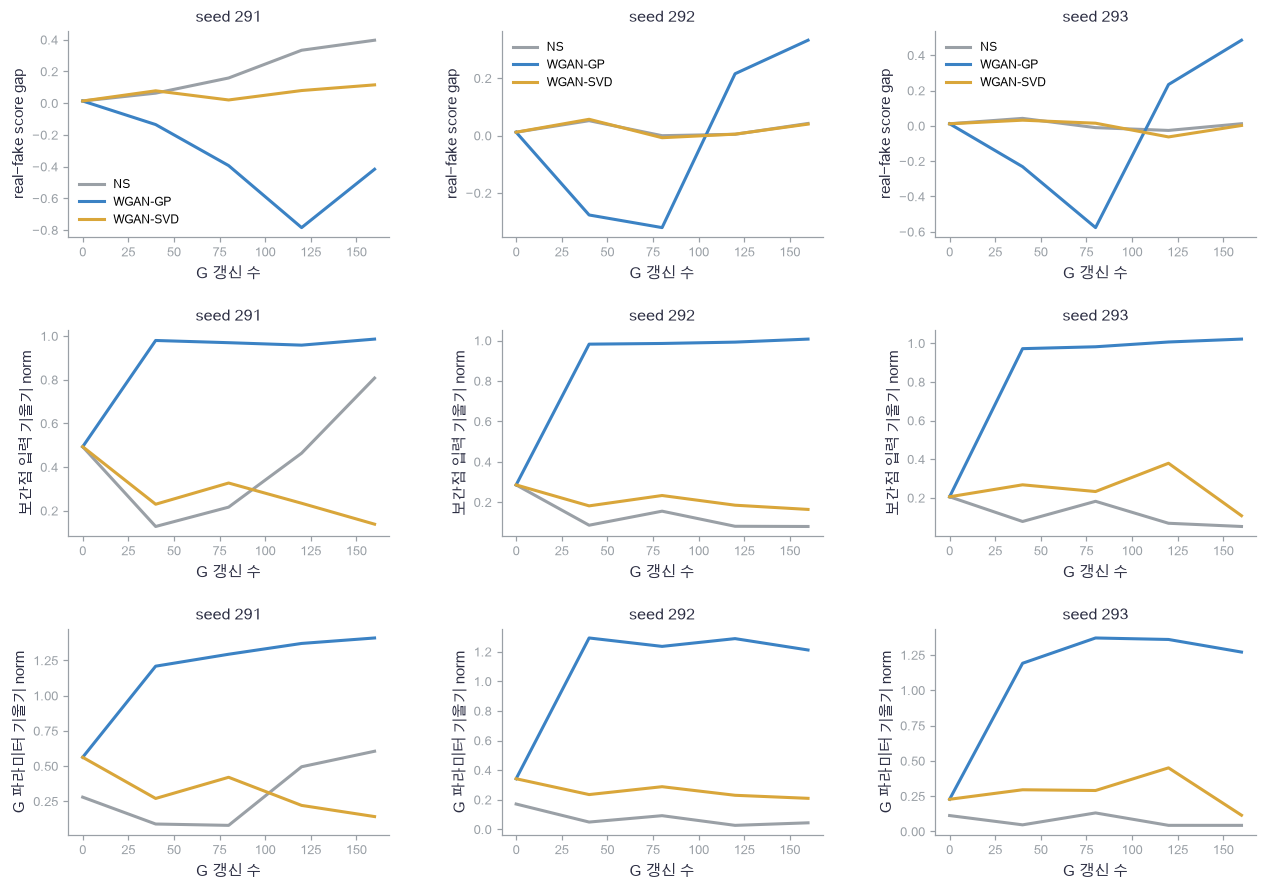

In [57]:
plot_training_diagnostics(histories, methods, seeds)

🔍 **확인** · 세 줄은 각각 critic의 점수 차, 보간점의 평균 입력 norm, G의 파라미터 기울기 norm입니다. GP의 평균 입력 norm이 1 근처로 가더라도 **평균 크기가 1 근처라는 진단**일 뿐입니다. 예를 들어 norm이 0.2와 1.8이면 평균은1이지만 GP는0.64입니다. 평균만으로 GP 자체가 작다거나 각 표본의 norm이1 근처라고 결론 낼 수 없습니다. 최종 품질은 다음 표와 생성 점으로 따로 확인합니다. 음의 critic gap도 유한 학습·제한된 critic에서 나올 수 있으며 음의 참 거리라는 뜻이 아닙니다.

In [58]:
# 쓰는 것: methods, seeds, metrics, histories, generated (5절 고정 실험)
print("seed method     quality coverage counts             mean_dist bound   sec")
for seed in seeds:
    for method in methods:
        result = metrics[(method, seed)]
        print(f"{seed} {method:10s} {result['quality']:.3f}   {result['coverage']:.2f}    "
              f"{str(result['counts'].tolist()):18s} {result['distance']:.3f}     {result['bound']:.3f}  {result['seconds']:.3f}")
all_points = np.concatenate(list(generated.values()))
plot_extent = max(3.2, float(np.max(np.abs(all_points))) + .2)
sample_limits = (-plot_extent, plot_extent)

seed method     quality coverage counts             mean_dist bound   sec
291 NS         0.082   1.00    [22, 17, 26, 19]   0.896     4.157  0.057
291 WGAN-GP    0.007   0.25    [0, 0, 0, 7]       1.024     2.718  0.070
291 WGAN-SVD   0.001   0.00    [0, 0, 1, 0]       1.369     1.000  0.061
292 NS         0.066   1.00    [11, 18, 19, 20]   0.968     1.415  0.057
292 WGAN-GP    0.034   0.50    [17, 0, 0, 18]     0.816     1.497  0.069
292 WGAN-SVD   0.035   1.00    [11, 7, 12, 6]     1.103     0.909  0.061
293 NS         0.062   1.00    [19, 9, 19, 16]    0.997     1.767  0.057
293 WGAN-GP    0.004   0.00    [1, 1, 0, 2]       0.838     1.960  0.070
293 WGAN-SVD   0.028   1.00    [6, 6, 8, 9]       1.205     0.812  0.061


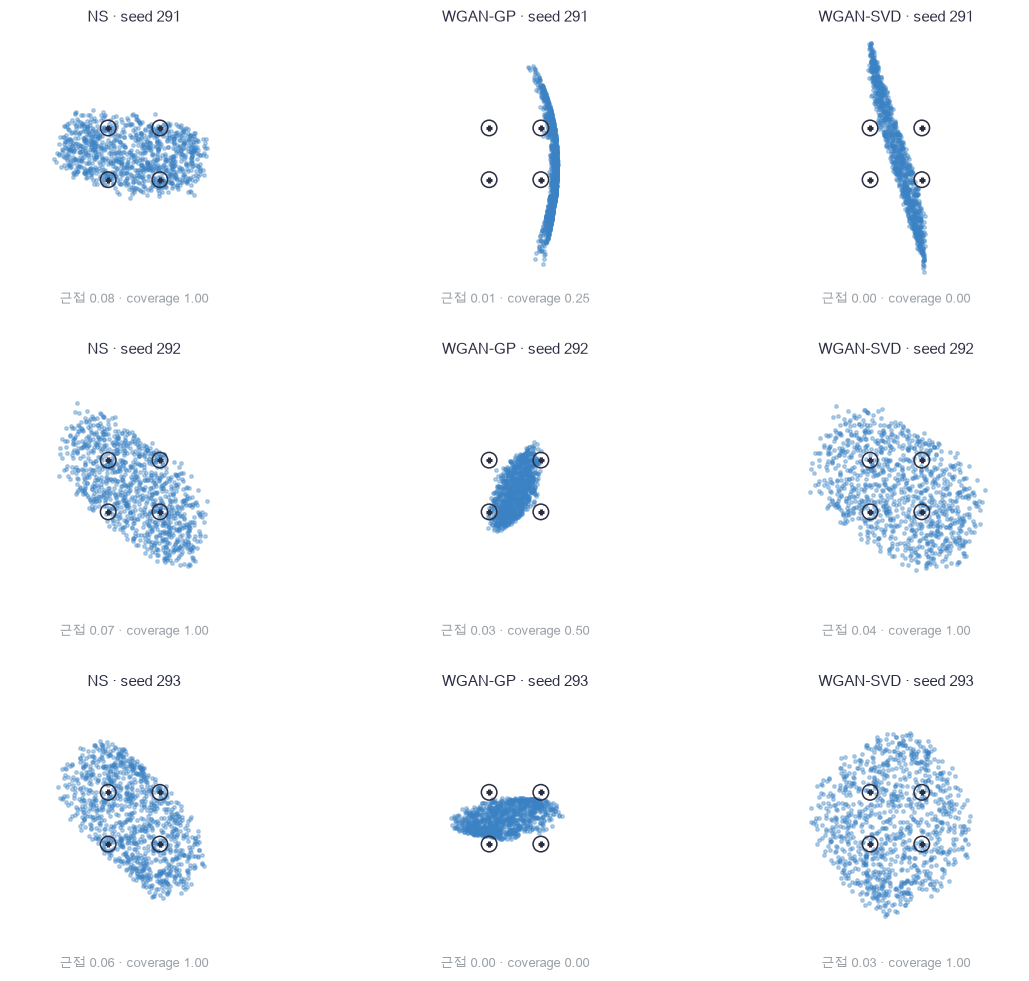

In [59]:
plot_seed_samples(generated, methods, seeds, centers, .3, metrics, sample_limits)

🔍 **확인** · 모든 방법과 seed를 같은 축에 그렸습니다. 축 범위는 **모든 생성점**을 포함하므로 멀리 있는 점을 자르지 않습니다. 원은 판정 반경이며 정답 이미지의 경계가 아닙니다.

이 고정된 짧은 실험에서는 세 방법 모두 실제 분포 표본보다 근접 비율이 훨씬 낮습니다. NS가 네 mode의 최소 개수를 채우더라도 대부분의 표본이 mode 밖일 수 있습니다. GP의 입력 norm이 1 근처여도 높은 품질이나 모든 mode의 발견이 따라오지 않습니다. 작은 critic의 표현력, 강한 제약, 짧은 학습, 교대 최적화가 함께 얽혀 있으므로 이 결과만으로 실패 원인 하나나 보편적 우승 방법을 정하지 않습니다.

세 seed는 제한된 반복 관찰입니다. radius·최소 개수·표본 수가 달라지면 지표도 달라집니다. 새로운 설정을 연구하려면 별도 사전 계획과 검증 자료로 설정을 고른 뒤 새 독립 평가를 해야 합니다. 여기서는 결과를 보고 예산을 늘리거나 잘 나온 seed를 골라 다시 보고하지 않았습니다.

In [60]:
# 쓰는 것: methods, seeds, metrics, histories (5절 고정 실험)
for method in methods:
    qualities = np.array([metrics[(method, seed)]["quality"] for seed in seeds])
    coverages = np.array([metrics[(method, seed)]["coverage"] for seed in seeds])
    print(f"{method:10s} · seed 평균±SD: 품질 {qualities.mean():.3f}±{qualities.std(ddof=1):.3f}, "
          f"coverage {coverages.mean():.2f}±{coverages.std(ddof=1):.2f}")
    for seed in seeds:
        assert histories[(method, seed)].shape == (5, 4), "5개 고정 진단 시점과4열을 기록해야 합니다"
        assert np.all(np.isfinite(histories[(method, seed)])), "모든 진단값은 유한해야 합니다"
        if method == "WGAN-SVD":
            assert metrics[(method, seed)]["bound"] <= 1 + 1e-10, "최종 투영 critic의 전역 상한은1이하여야 합니다"
print("고정 진단 횟수·유한값·투영 제약 검산 통과")

NS         · seed 평균±SD: 품질 0.070±0.011, coverage 1.00±0.00
WGAN-GP    · seed 평균±SD: 품질 0.015±0.017, coverage 0.25±0.25
WGAN-SVD   · seed 평균±SD: 품질 0.021±0.018, coverage 0.67±0.58
고정 진단 횟수·유한값·투영 제약 검산 통과


📎 **참고** · `std(ddof=1)`은 seed 세 개 사이의 표본 표준편차입니다. 초기값·학습 표본·평가 잡음의 변화가 함께 들어 있으므로 순수 평가 Monte Carlo 표준오차와 같지 않습니다. 방법 간 차이를 읽을 때는 같은 seed끼리 짝지어진 결과를 먼저 보세요.

**구조·목적·optimizer·사용을 다시 구분합니다.** 구조는 두 tanh MLP이고, 목적은 NS 또는 Wasserstein 기본항과 GP입니다. Adam은 그 목적의 미분으로 갱신하는 규칙입니다. SVD 투영은 갱신 뒤 제약입니다. 학습 후 표본을 만들 때는 $z\sim\mathcal N(0,I)$를 뽑아 $G(z)$만 계산하며 critic이나 GP를 호출하지 않습니다. 이 GAN은 $p(x)$의 값을 계산하는 모델이 아닙니다.

### ✏️ 연습 5 · coverage만으로 품질을 대신하지 않기

반경 안 판정 accepted 전체의 평균 quality를 채우세요. False 표본도 분모에 포함합니다.

In [61]:
def exercise_quality(accepted):
    """coverage만으로 품질을 대신하지 않기의 핵심 계산을 완성합니다."""
    ### 이 주석 아래에 다음을 구현하세요.
    ### 구현할 내용: 반경 안 판정 accepted 전체의 평균 quality를 채우세요. False 표본도 분모에 포함합니다.
    raise NotImplementedError
    return quality

In [62]:
def check_quality(candidate):
    """손계산과 경계 입력으로 정답을 독립 확인합니다."""
    assert np.isclose(candidate(np.array([True, False, False, False])), .25), "분모는 근접 표본1개가 아니라 전체4개입니다"
    assert candidate(np.array([False, False])) == 0, "전부 멀면 품질0이어야 합니다"
    print("연습 5 통과")

run_check(check_quality, exercise_quality, hint="coverage만으로 품질을 대신하지 않기의 수식을 한 줄씩 옮겨 보세요.")

☐ exercise_quality: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: coverage만으로 품질을 대신하지 않기의 수식을 한 줄씩 옮겨 보세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
quality = np.mean(accepted)
```

</details>

## ✏️ 끝 연습 · A–D

한두 줄만 채우되 손으로 예상한 값부터 적어 보세요. 본문 모델 함수는 이미 완성되어 있으므로 연습을 풀지 않아도 실험은 실행됩니다.

### ✏️ 연습 A · Wasserstein critic의 두 평균

실제·가짜 점수의 평균을 이용하여 최소화할 critic loss를 채우세요.

In [63]:
def exercise_wloss(real_scores, fake_scores):
    """Wasserstein critic의 두 평균의 핵심 계산을 완성합니다."""
    ### 이 주석 아래에 다음을 구현하세요.
    ### 구현할 내용: 실제·가짜 점수의 평균을 이용하여 최소화할 critic loss를 채우세요.
    raise NotImplementedError
    return loss

In [64]:
def check_wloss(candidate):
    """손계산과 경계 입력으로 정답을 독립 확인합니다."""
    assert np.isclose(candidate(np.array([1., 3.]), np.array([-2.])), -4), "서로 다른 표본 수의 평균은 각각 계산합니다"
    assert np.isclose(candidate(np.array([11., 13.]), np.array([8.])), -4), "공통 점수 이동은 gap을 바꾸지 않습니다"
    print("연습 A 통과")

run_check(check_wloss, exercise_wloss, hint="Wasserstein critic의 두 평균의 수식을 한 줄씩 옮겨 보세요.")

☐ exercise_wloss: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: Wasserstein critic의 두 평균의 수식을 한 줄씩 옮겨 보세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
loss = np.mean(fake_scores) - np.mean(real_scores)
```

</details>

### ✏️ 연습 B · GP의 W에는 두 경로가 있습니다

직접 경로 v.T @ weighted_slope와 간접 경로 x.T @ du를 더한 dw를 채우세요.

In [65]:
def exercise_gp_dw(v, weighted_slope, x, du):
    """GP의 W에는 두 경로가 있습니다의 핵심 계산을 완성합니다."""
    ### 이 주석 아래에 다음을 구현하세요.
    ### 구현할 내용: 직접 경로 v.T @ weighted_slope와 간접 경로 x.T @ du를 더한 dw를 채우세요.
    raise NotImplementedError
    return dw

In [66]:
def check_gp_dw(candidate):
    """손계산과 경계 입력으로 정답을 독립 확인합니다."""
    v = np.array([[1., 2.]])
    slope = np.array([[3., 4.]])
    x = np.array([[5., 6.]])
    du = np.array([[7., 8.]])
    np.testing.assert_allclose(candidate(v, slope, x, du), [[38., 44.], [48., 56.]])  # 검산: 직접+간접 두 외적
    print("연습 B 통과")

run_check(check_gp_dw, exercise_gp_dw, hint="GP의 W에는 두 경로가 있습니다의 수식을 한 줄씩 옮겨 보세요.")

☐ exercise_gp_dw: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: GP의 W에는 두 경로가 있습니다의 수식을 한 줄씩 옮겨 보세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
dw = v.T @ weighted_slope + x.T @ du
```

</details>

### ✏️ 연습 C · 층별 상한을 연결하기

주어진 W_norm과 a_norm을 곱해 전체 critic의 bound를 채우세요.

In [67]:
def exercise_bound(W_norm, a_norm):
    """층별 상한을 연결하기의 핵심 계산을 완성합니다."""
    ### 이 주석 아래에 다음을 구현하세요.
    ### 구현할 내용: 주어진 W_norm과 a_norm을 곱해 전체 critic의 bound를 채우세요.
    raise NotImplementedError
    return bound

In [68]:
def check_bound(candidate):
    """손계산과 경계 입력으로 정답을 독립 확인합니다."""
    assert np.isclose(candidate(.5, .8), .4), "tanh 상한1을 포함한 곱은.4여야 합니다"
    assert np.isclose(candidate(2., .3), .6), "각 층1이하는 충분조건이며 곱으로 상한을 구합니다"
    print("연습 C 통과")

run_check(check_bound, exercise_bound, hint="층별 상한을 연결하기의 수식을 한 줄씩 옮겨 보세요.")

☐ exercise_bound: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 층별 상한을 연결하기의 수식을 한 줄씩 옮겨 보세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
bound = W_norm * a_norm
```

</details>

### ✏️ 연습 D · 최소 개수를 바꿔 coverage를 다시 읽기

근접 표본 개수 counts가 minimum 이상인 중심의 비율 coverage를 채우세요.

In [69]:
def exercise_coverage(counts, minimum):
    """최소 개수를 바꿔 coverage를 다시 읽기의 핵심 계산을 완성합니다."""
    ### 이 주석 아래에 다음을 구현하세요.
    ### 구현할 내용: 근접 표본 개수 counts가 minimum 이상인 중심의 비율 coverage를 채우세요.
    raise NotImplementedError
    return coverage

In [70]:
def check_coverage(candidate):
    """손계산과 경계 입력으로 정답을 독립 확인합니다."""
    assert candidate(np.array([5, 4, 0, 11]), 5) == .5, "최소5를 채운 중심은4개 중2개입니다"
    assert candidate(np.array([5, 4, 0, 11]), 1) == .75, "최소1로 바꾸면4개 중3개입니다"
    print("연습 D 통과")

run_check(check_coverage, exercise_coverage, hint="최소 개수를 바꿔 coverage를 다시 읽기의 수식을 한 줄씩 옮겨 보세요.")

☐ exercise_coverage: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 최소 개수를 바꿔 coverage를 다시 읽기의 수식을 한 줄씩 옮겨 보세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
coverage = np.mean(counts >= minimum)
```

</details>

## ✏️ 준비도 · 설명·수식·구현·변형 검산

- **설명:** 최적 분류기가 두 점질량을 완벽히 구분해도 이동 거리가 다른 이유를 설명할 수 있나요? critic gap, GP norm, 생성 품질은 각각 무엇을 재나요?
- **수식:** $g=(s\odot a)W^T$에서 GP의 $dW$ 두 항을 유도할 수 있나요? $g=0$일 때 벌점과 미분을 구분할 수 있나요?
- **구현:** G/D 상태·갱신 시계를 나누고 G 단계에서 critic 파라미터 미분을 버리는 위치를 짚을 수 있나요? 모든 방법이 같은 초기 배열과 표본 계획을 받는지 검산할 수 있나요?
- **변형 검산:** `diag(2,.5)`를 투영하는 것과 전체를 2로 나누는 것을 비교할 수 있나요? 모든 표본이 반경 밖일 때 quality와 coverage가 함께 0인지, 최소 개수만 바꾸면 coverage가 어떻게 달라지는지 확인할 수 있나요?

본문의 다섯 절과 절 연습을 설명하며 통과하면 [30 flow](30_normalizing_flow.ipynb)로 넘어갈 준비가 되었습니다. GAN은 표본 비교로 학습했고, flow는 변환의 부피 변화를 계산해 우도를 직접 학습한다는 차이를 이어 봅니다. 표본 기반 비교의 한계는 [37 평가](37_generative_evaluation.ipynb)와 연결됩니다.